Original shape: (7043, 21)
Missing values before cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicate records: 0
Cleaned shape: (7032, 21)
Churn distribution:
Churn
No     5163
Yes    1869
Name: count, dtype: int64


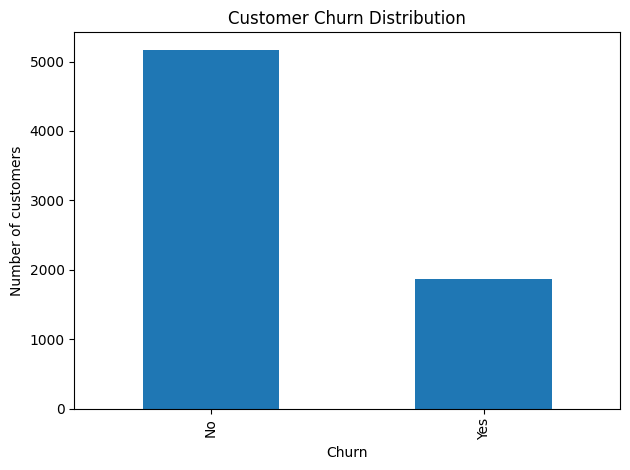

Training: Logistic Regression


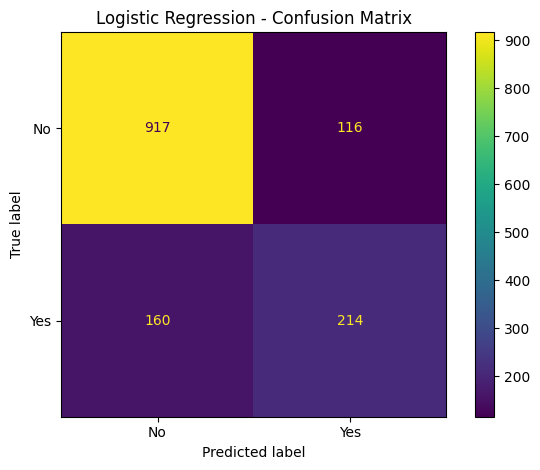

Training: Decision Tree


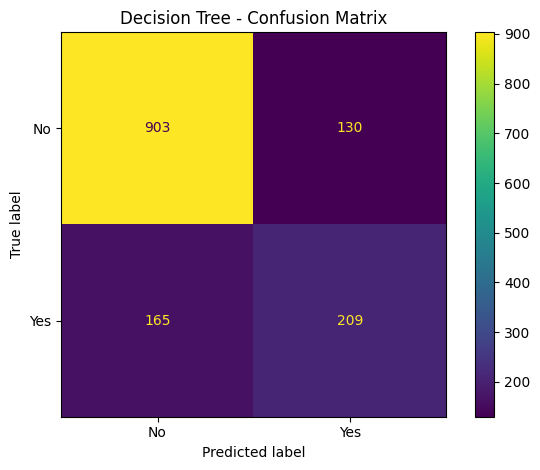

Training: Random Forest


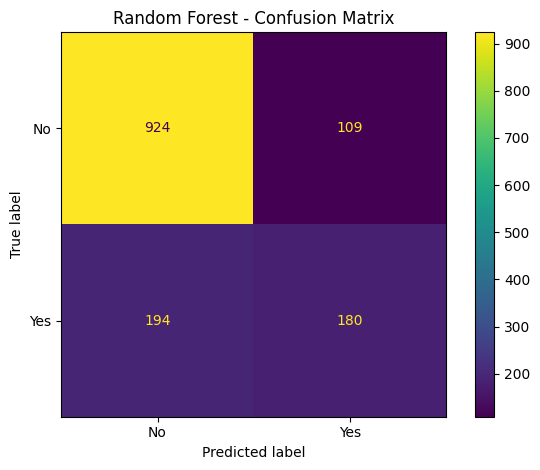

Training: SVM


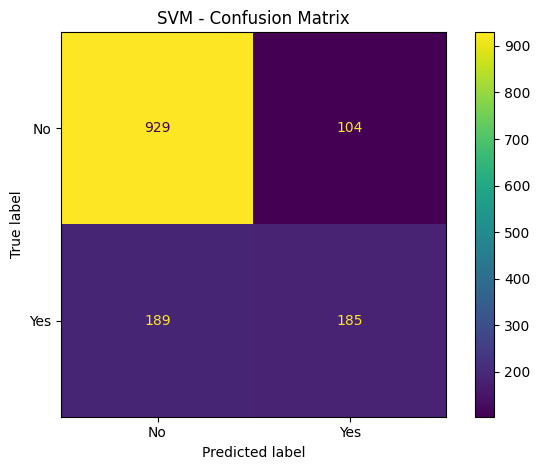


MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359
1,Decision Tree,0.7903,0.6165,0.5588,0.5863,0.8232
3,SVM,0.7918,0.6401,0.4947,0.5581,0.7886
2,Random Forest,0.7846,0.6228,0.4813,0.5430,0.8142


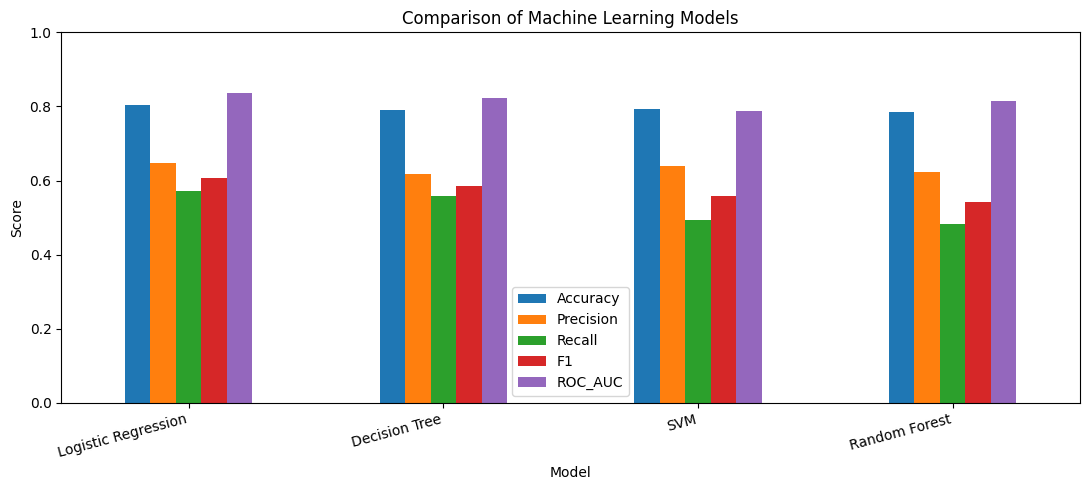

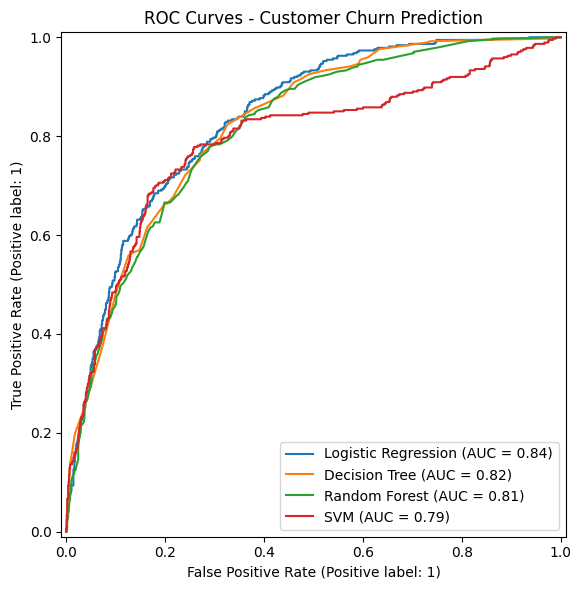


Best model by F1: Logistic Regression


,Feature,Importance
4,tenure,0.271561
7,InternetService,0.154274
14,Contract,0.141880
11,TechSupport,0.045205
8,OnlineSecurity,0.036091
17,MonthlyCharges,0.029118
16,PaymentMethod,0.028690
15,PaperlessBilling,0.026889
18,TotalCharges,0.026312
10,DeviceProtection,0.023043


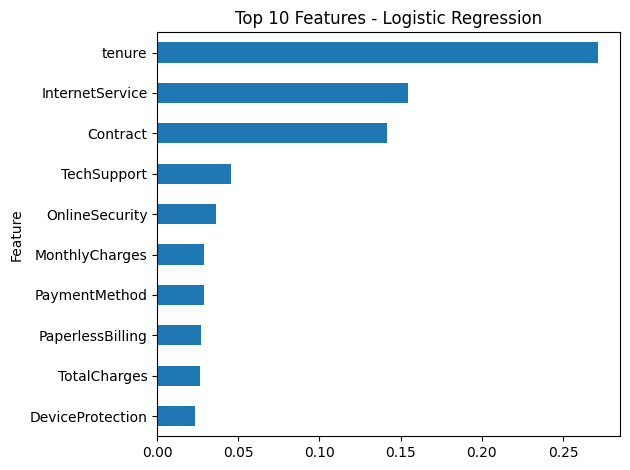

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Experiment complete. Results saved.


In [ ]:

# CUSTOMER CHURN PREDICTION - COMPLETE EXPERIMENT

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay
)
from sklearn.inspection import permutation_importance

# 1. Create output folder
os.makedirs("churn_results", exist_ok=True)

# 2. Download and inspect data
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)
df = pd.read_csv(url)

print("Original shape:", df.shape)
print("Missing values before cleaning:")
print(df.isna().sum())
print("Duplicate records:", df.duplicated().sum())

# 3. Clean dataset
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
df = df.drop_duplicates(subset=["customerID"])
df = df.dropna(subset=["TotalCharges"])

print("Cleaned shape:", df.shape)
print("Churn distribution:")
print(df["Churn"].value_counts())

df.to_csv("churn_results/cleaned_telco.csv", index=False)

# 4. Exploratory data analysis
ax = df["Churn"].value_counts().plot(
    kind="bar", title="Customer Churn Distribution"
)
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("churn_results/churn_distribution.png")
plt.show()

# 5. Prepare features and target
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

categorical = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()
numerical = X.select_dtypes(
    include=["number"]
).columns.tolist()

# 6. Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 7. Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical),
    ("cat", categorical_pipeline, categorical)
])

# 8. Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42, max_depth=6
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=42, n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", probability=True, random_state=42
    )
}

results = []
trained_models = {}

# 9. Train and evaluate each model
for name, model in models.items():
    print("Training:", name)

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["No", "Yes"]
    )
    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()
    plt.savefig(
        "churn_results/" +
        name.replace(" ", "_") + "_confusion.png"
    )
    plt.show()

# 10. Save comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "F1", ascending=False
)

print("\nMODEL COMPARISON")
display(results_df.round(4))

results_df.to_csv(
    "churn_results/model_comparison.csv", index=False
)

# 11. Model comparison chart
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
].plot(kind="bar", figsize=(11, 5))

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("churn_results/model_comparison.png")
plt.show()

# 12. ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

for name, pipeline in trained_models.items():
    RocCurveDisplay.from_estimator(
        pipeline, X_test, y_test, ax=ax, name=name
    )

plt.title("ROC Curves - Customer Churn Prediction")
plt.tight_layout()
plt.savefig("churn_results/roc_curves.png")
plt.show()

# 13. Feature importance for best F1 model
best_name = results_df.iloc[0]["Model"]
best_pipeline = trained_models[best_name]

importance = permutation_importance(
    best_pipeline, X_test, y_test,
    scoring="f1", n_repeats=3,
    random_state=42, n_jobs=-1
)

feature_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

feature_df.to_csv(
    "churn_results/feature_importance.csv", index=False
)

print("\nBest model by F1:", best_name)
display(feature_df.head(10))

feature_df.head(10).sort_values(
    "Importance"
).plot.barh(x="Feature", y="Importance", legend=False)

plt.title("Top 10 Features - " + best_name)
plt.tight_layout()
plt.savefig("churn_results/feature_importance.png")
plt.show()

# 14. Package outputs for download
import shutil
shutil.make_archive(
    "Customer_Churn_Results", "zip", "churn_results"
)

from google.colab import files
files.download("Customer_Churn_Results.zip")

print("Experiment complete. Results saved.")


CLASS-WEIGHTED MODEL RESULTS


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.7257,0.4901,0.7968,0.6069,0.8351
1,Decision Tree,0.7335,0.4992,0.7995,0.6146,0.8182
2,Random Forest,0.7861,0.6281,0.4786,0.5432,0.8124
3,SVM,0.7257,0.4899,0.7754,0.6004,0.8083


,Model,Accuracy_Baseline,Precision_Baseline,Recall_Baseline,F1_Baseline,ROC_AUC_Baseline,Accuracy_Balanced,Precision_Balanced,Recall_Balanced,F1_Balanced,ROC_AUC_Balanced
0,Logistic Regression,0.8038,0.6485,0.5722,0.6080,0.8359,0.7257,0.4901,0.7968,0.6069,0.8351
1,Decision Tree,0.7903,0.6165,0.5588,0.5863,0.8232,0.7335,0.4992,0.7995,0.6146,0.8182
2,SVM,0.7918,0.6401,0.4947,0.5581,0.7886,0.7257,0.4899,0.7754,0.6004,0.8083
3,Random Forest,0.7846,0.6228,0.4813,0.5430,0.8142,0.7861,0.6281,0.4786,0.5432,0.8124


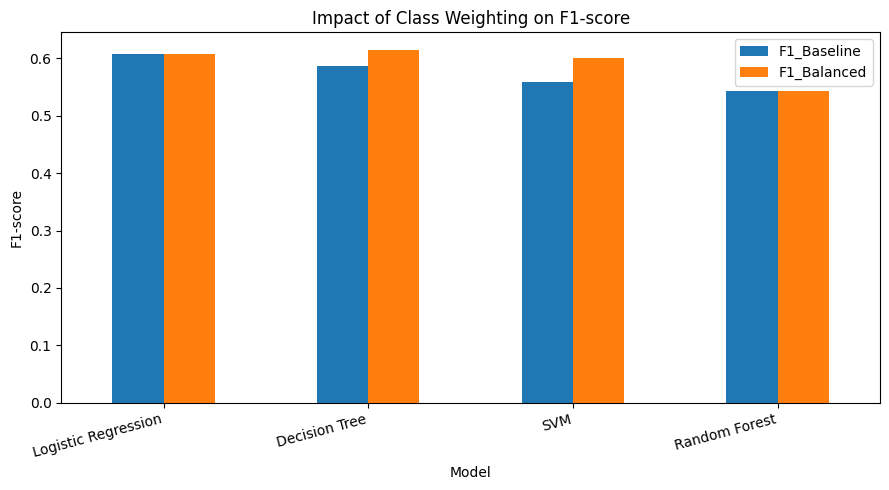

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# EXPERIMENT 2: CLASS IMBALANCE HANDLING

balanced_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", probability=True,
        class_weight="balanced", random_state=42
    )
}

balanced_results = []

for name, model in balanced_models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    balanced_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    })

balanced_df = pd.DataFrame(balanced_results)

print("CLASS-WEIGHTED MODEL RESULTS")
display(balanced_df.round(4))

balanced_df.to_csv(
    "churn_results/balanced_model_comparison.csv",
    index=False
)

# Compare baseline and class-weighted models
comparison = results_df.merge(
    balanced_df,
    on="Model",
    suffixes=("_Baseline", "_Balanced")
)

comparison.to_csv(
    "churn_results/imbalance_comparison.csv",
    index=False
)

display(comparison.round(4))

# Visualise F1-score comparison
comparison.plot(
    x="Model",
    y=["F1_Baseline", "F1_Balanced"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Impact of Class Weighting on F1-score")
plt.ylabel("F1-score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("churn_results/imbalance_comparison.png")
plt.show()

# Download updated results
import shutil
shutil.make_archive(
    "Customer_Churn_Updated_Results",
    "zip",
    "churn_results"
)

from google.colab import files
files.download("Customer_Churn_Updated_Results.zip")


Evaluating: Baseline - Logistic Regression
Evaluating: Baseline - Decision Tree
Evaluating: Baseline - Random Forest
Evaluating: Baseline - SVM
Evaluating: Class Weighted - Logistic Regression
Evaluating: Class Weighted - Decision Tree
Evaluating: Class Weighted - Random Forest
Evaluating: Class Weighted - SVM

CROSS-VALIDATION RESULTS


,Experiment,Model,Accuracy_Mean,Accuracy_Std,Precision_Mean,Precision_Std,Recall_Mean,Recall_Std,F1_Mean,F1_Std,ROC_AUC_Mean,ROC_AUC_Std
4,Class Weighted,Logistic Regression,0.7520,0.0051,0.5218,0.0065,0.8020,0.0143,0.6322,0.0070,0.8459,0.0054
7,Class Weighted,SVM,0.7476,0.0039,0.5165,0.0048,0.7853,0.0193,0.6231,0.0081,0.8261,0.0072
5,Class Weighted,Decision Tree,0.7351,0.0116,0.5016,0.0143,0.7853,0.0286,0.6118,0.0113,0.8154,0.0094
0,Baseline,Logistic Regression,0.8025,0.0116,0.6541,0.0289,0.5465,0.0229,0.5953,0.0229,0.8461,0.0052
1,Baseline,Decision Tree,0.7877,0.0087,0.6225,0.0244,0.5164,0.0478,0.5628,0.0282,0.8251,0.0072
3,Baseline,SVM,0.8005,0.0065,0.6769,0.0303,0.4816,0.0129,0.5621,0.0031,0.8002,0.0133
2,Baseline,Random Forest,0.7913,0.0075,0.6379,0.0175,0.4970,0.0313,0.5582,0.0225,0.8252,0.0077
6,Class Weighted,Random Forest,0.7941,0.0084,0.6509,0.0187,0.4856,0.0270,0.5560,0.0231,0.8248,0.0085


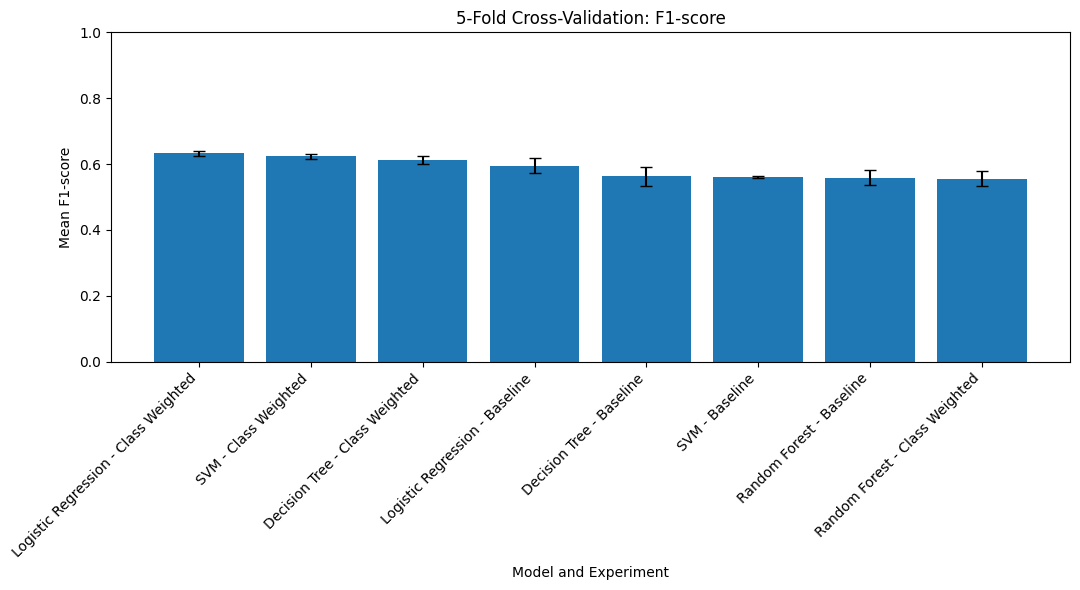

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cross-validation completed successfully!


In [ ]:

# EXPERIMENT 3: STRATIFIED 5-FOLD CROSS-VALIDATION

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline

# 1. Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 2. Evaluation metrics
scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# 3. Evaluate baseline and class-weighted models
cv_results = []

experiments = {
    "Baseline": models,
    "Class Weighted": balanced_models
}

for experiment_name, model_group in experiments.items():

    for model_name, model in model_group.items():

        print(
            "Evaluating:",
            experiment_name,
            "-",
            model_name
        )

        pipeline = Pipeline([
            ("preprocessing", preprocessor),
            ("classifier", model)
        ])

        scores = cross_validate(
            pipeline,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            n_jobs=-1,
            error_score="raise"
        )

        row = {
            "Experiment": experiment_name,
            "Model": model_name
        }

        for metric in scoring:
            values = scores["test_" + metric]

            row[metric + "_Mean"] = values.mean()
            row[metric + "_Std"] = values.std()

        cv_results.append(row)

# 4. Create results table
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    "F1_Mean",
    ascending=False
)

print("\nCROSS-VALIDATION RESULTS")
display(cv_df.round(4))

# 5. Save results
cv_df.to_csv(
    "churn_results/cross_validation_results.csv",
    index=False
)

# 6. Visualise mean F1-score
plot_df = cv_df.copy()

plot_df["Model_Experiment"] = (
    plot_df["Model"] + " - " +
    plot_df["Experiment"]
)

plt.figure(figsize=(11, 6))

plt.bar(
    plot_df["Model_Experiment"],
    plot_df["F1_Mean"],
    yerr=plot_df["F1_Std"],
    capsize=4
)

plt.title("5-Fold Cross-Validation: F1-score")
plt.xlabel("Model and Experiment")
plt.ylabel("Mean F1-score")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    "churn_results/cross_validation_f1.png",
    dpi=300
)

plt.show()

# 7. Download updated results
import shutil
from google.colab import files

shutil.make_archive(
    "Customer_Churn_Final_Results",
    "zip",
    "churn_results"
)

files.download("Customer_Churn_Final_Results.zip")

print("Cross-validation completed successfully!")


In [ ]:

import joblib
import sklearn
from google.colab import files

# Train the selected class-weighted model
final_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

final_pipeline.fit(X_train, y_train)

# Save the fitted preprocessing and prediction pipeline
joblib.dump(final_pipeline, "churn_pipeline.joblib")

print("Scikit-learn version:", sklearn.__version__)
print("Model saved successfully!")

files.download("churn_pipeline.joblib")


Scikit-learn version: 1.6.1
Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>